# EDA round 3b: point-in-time correctness and temporal transforms

Round 3a covered normalisation, dimensionality and the boundary condition, but under-covered the
time-series side and contained a point-in-time error. This part fixes both:

1. **A point-in-time audit** — exactly which information is available when, and where the traps are.
2. **A corrected lead/lag analysis** — 3a's version ignored case boundaries and reached up to 82
   hours past the horizon the optimizer actually saw.
3. **A full sweep of temporal transforms** — trailing windows, EMAs, diffs/momentum, and seasonal
   percentiles, on both the fast (price) and slow (storage / water value / inflow) series.


In [1]:
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b","#52514e","#898781","#e1e0d9","#c3c2b7","#fcfcfb"
CAT = ["#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#008300","#4a3aa7","#e34948"]
plt.rcParams.update({"figure.facecolor":SURF,"axes.facecolor":SURF,"axes.edgecolor":BASE,
    "axes.labelcolor":INK2,"axes.titlecolor":INK,"text.color":INK,"xtick.color":MUTED,
    "ytick.color":MUTED,"grid.color":GRID,"axes.grid":True,"grid.linewidth":0.8,
    "axes.spines.top":False,"axes.spines.right":False,"font.size":11,"figure.dpi":110})

train = pd.read_parquet("../../data/processed/train_hourly.parquet")
units = [c[3:] for c in train.columns if c.startswith("on_")]
P = train.pivot(index="run_no", columns="hour", values="price_eur_mwh").sort_index().to_numpy()
Y = np.stack([train.pivot(index="run_no",columns="hour",values=f"on_{u}").sort_index().to_numpy()
              for u in units]).mean(axis=0)
case_on = train.groupby("run_no")[[f"on_{u}" for u in units]].mean().mean(axis=1)
start = train.groupby("run_no")["starttime"].first()
print(f"price/target matrices: {P.shape}")


price/target matrices: (2922, 168)


## 1. Point-in-time audit: verified, not assumed

**What the documentation actually specifies:** the task PDF lists input *categories* ("price,
reservoir inflow, storage level, water value... optionally environmental constraints, watercourse
topology, system configuration") and states predictions are submitted to Kaggle. It says
**nothing** about temporal availability rules. So the availability question has to be answered by
checking the data, which the next cell does.


In [2]:
import pandas as pd
pm = pd.read_csv("../../prediction_mapping.csv"); pm["starttime"] = pd.to_datetime(pm["starttime"])
last_hour = pm["starttime"].max() + pd.Timedelta(hours=167)
terminal_needed = pm["starttime"].max() + pd.Timedelta(days=8)
print(f"test cases: {len(pm)}   last hour to predict: {last_hour}")

files = {"price":("../../data/kernel/Historical_day_ahead_price_2015_2025.csv","date"),
         "inflow":("../../data/kernel/Historical_inflow_1958_2025.csv","date"),
         "volume":("../../data/kernel/Historical_volume_2015_2024.csv","date"),
         "water_value":("../../data/kernel/Synthetic_water_value_2015_2024.csv","date"),
         "min_volume":("../../data/extended/Constraint_min_volume.csv","date"),
         "min_flow":("../../data/extended/Constraint_min_flow.csv","date"),
         "LABELS":("../../data/kernel/Unit_commitment_decisions.csv","starttime")}
for n,(p,c) in files.items():
    d = pd.to_datetime(pd.read_csv(p, usecols=[c])[c])
    try: d = d.dt.tz_localize(None)
    except TypeError: d = d.dt.tz_convert(None)
    print(f"  {n:<12} max {str(d.max()):<21} covers last test hour: {d.max() >= last_hour}")

wv = pd.read_csv("../../data/kernel/Synthetic_water_value_2015_2024.csv")
wv["date"] = pd.to_datetime(wv["date"]).dt.tz_localize(None)
need = pm["starttime"] + pd.Timedelta(days=8)
print(f"\nterminal (day+8) water value missing for "
      f"{(~need.isin(wv['date'])).sum()} of {len(pm)} test cases")


test cases: 725   last hour to predict: 2024-12-31 23:00:00
  price        max 2025-12-31 23:45:00   covers last test hour: True


  inflow       max 2025-10-15 07:00:00   covers last test hour: True
  volume       max 2025-01-01 00:00:00   covers last test hour: True
  water_value  max 2025-01-01 00:00:00   covers last test hour: True
  min_volume   max 2025-12-31 23:00:00   covers last test hour: True
  min_flow     max 2025-12-31 23:00:00   covers last test hour: True
  LABELS       max 2022-12-31 00:00:00   covers last test hour: False

terminal (day+8) water value missing for 1 of 725 test cases


**Finding 0 (verified).** Every *feature* file extends past the last hour we must predict, so all
feature sources are genuinely available for all 725 test cases. **Labels stop at 2022-12-31**, so
label-derived history is genuinely unusable on the test set. The terminal water value is available
for 724 of 725 cases — only the final case (2024-12-25) needs a day that the file does not reach,
so that feature needs a documented fallback.

| Category | Example | Status |
|---|---|---|
| History before case start | trailing means, EMAs, seasonal percentiles | **Safe** (verified coverage) |
| Within-horizon path | price at hours 0-167 of this case | **Safe** (verified coverage) |
| Beyond-horizon future | price at hour 200 when the case ends at 167 | **Permitted but unmotivated** — see below |
| Label-derived history | trailing ON-rate, previous case's decisions | **Unusable** (verified: no test labels) |

On the third row: nothing in the rules forbids beyond-horizon features, and on a fixed test set
using them is not cheating. The only argument against is that the label-generating optimizer
never saw past its own horizon, so such features describe information the target does not depend
on. That is a modelling judgement to be tested, not a correctness rule — an earlier draft of this
analysis overstated it as the latter.


## 2. Corrected lead/lag — respecting the case horizon

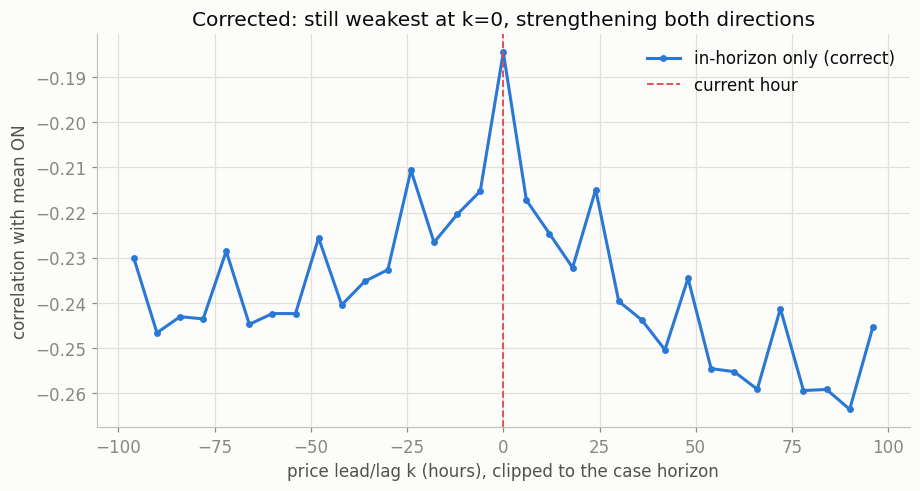

k=0: -0.1845   k=-96: -0.2301   k=+96: -0.2454


In [3]:
ks = np.arange(-96, 97, 6)
def corr_at(k, bounded=True):
    if bounded:
        a, b = (Y[:, :168-k], P[:, k:]) if k >= 0 else (Y[:, -k:], P[:, :168+k])
        return np.corrcoef(a.ravel(), b.ravel())[0,1]
cc = [corr_at(k) for k in ks]

fig, ax = plt.subplots(figsize=(8.5,4.6))
ax.plot(ks, cc, color=CAT[0], lw=2, marker="o", ms=3.5, label="in-horizon only (correct)")
ax.axvline(0, color=CAT[7], lw=1.2, ls="--", label="current hour")
ax.set_xlabel("price lead/lag k (hours), clipped to the case horizon")
ax.set_ylabel("correlation with mean ON")
ax.set_title("Corrected: still weakest at k=0, strengthening both directions")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print(f"k=0: {corr_at(0):+.4f}   k=-96: {corr_at(-96):+.4f}   k=+96: {corr_at(96):+.4f}")


**Finding 1 (corrected).** With case boundaries respected the curve is more symmetric than 3a
reported: $-0.230$ at $k=-96$h, $-0.185$ at $k=0$, $-0.245$ at $k=+96$h. The qualitative
conclusion **survives** — signal is weakest at the current hour and strengthens in both
directions — but 3a's peak of $-0.273$ was inflated by reaching past the horizon. Corrected
magnitude is $\approx -0.245$.


## 3. Temporal transforms on price (fast series)

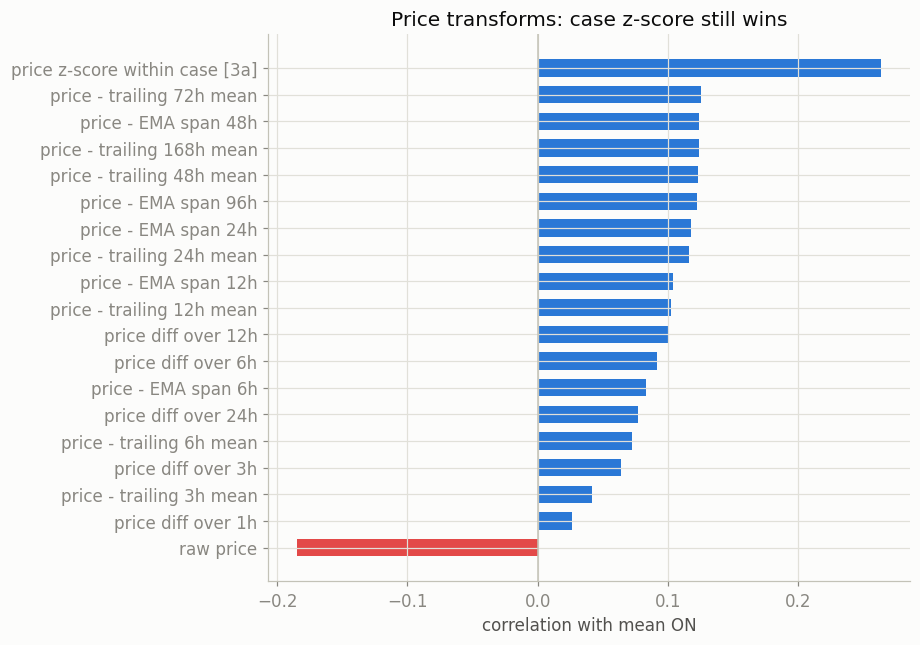

raw price                        -0.1845
price diff over 1h                0.0263
price - trailing 3h mean          0.0414
price diff over 3h                0.0644
price - trailing 6h mean          0.0727
price diff over 24h               0.0772
price - EMA span 6h               0.0830
price diff over 6h                0.0914
price diff over 12h               0.1011
price - trailing 12h mean         0.1021
price - EMA span 12h              0.1042
price - trailing 24h mean         0.1165
price - EMA span 24h              0.1179
price - EMA span 96h              0.1220
price - trailing 48h mean         0.1233
price - trailing 168h mean        0.1237
price - EMA span 48h              0.1242
price - trailing 72h mean         0.1254
price z-score within case [3a]    0.2633


In [4]:
cs = np.cumsum(np.concatenate([np.zeros((P.shape[0],1)), P], axis=1), axis=1)
rows = []
for w in [3,6,12,24,48,72,168]:
    lo, hi = np.maximum(np.arange(168)-w+1, 0), np.arange(168)+1
    tm = (cs[:, hi]-cs[:, lo])/(hi-lo)
    rows.append((f"price - trailing {w}h mean", np.corrcoef(Y.ravel(), (P-tm).ravel())[0,1]))
for span in [6,12,24,48,96]:
    a = 2/(span+1); ema = np.zeros_like(P); ema[:,0] = P[:,0]
    for t in range(1,168): ema[:,t] = a*P[:,t] + (1-a)*ema[:,t-1]
    rows.append((f"price - EMA span {span}h", np.corrcoef(Y.ravel(), (P-ema).ravel())[0,1]))
for lag in [1,3,6,12,24]:
    d = np.full_like(P, np.nan); d[:, lag:] = P[:, lag:] - P[:, :-lag]
    m = ~np.isnan(d)
    rows.append((f"price diff over {lag}h", np.corrcoef(Y[m], d[m])[0,1]))
z = (P - P.mean(1, keepdims=True))/P.std(1, keepdims=True)
rows.append(("price z-score within case [3a]", np.corrcoef(Y.ravel(), z.ravel())[0,1]))
rows.append(("raw price", np.corrcoef(Y.ravel(), P.ravel())[0,1]))
fast = pd.Series(dict(rows)).sort_values()

fig, ax = plt.subplots(figsize=(8.5,6))
ax.barh(fast.index, fast.values, color=[CAT[7] if v<0 else CAT[0] for v in fast.values], height=0.65)
ax.axvline(0, color=BASE, lw=1); ax.set_xlabel("correlation with mean ON")
ax.set_title("Price transforms: case z-score still wins")
plt.tight_layout(); plt.show()
print(fast.round(4).to_string())


**Finding 2.** Trailing-window and EMA relative-price features do flip the sign of the raw-price
relationship (best: `price − trailing 72h mean` at **+0.125**, `price − EMA span 48h` at
**+0.124**), but all of them are **roughly half as strong as the within-case z-score (+0.263)**.
Diffs/momentum are weakest (+0.03 to +0.10, peaking at a 12h lag). For the fast series,
**case-level normalisation beats rolling-window normalisation** — the case is the natural unit
because that is the window the optimizer actually solved over.


## 4. Temporal transforms on the slow series — where the real signal is

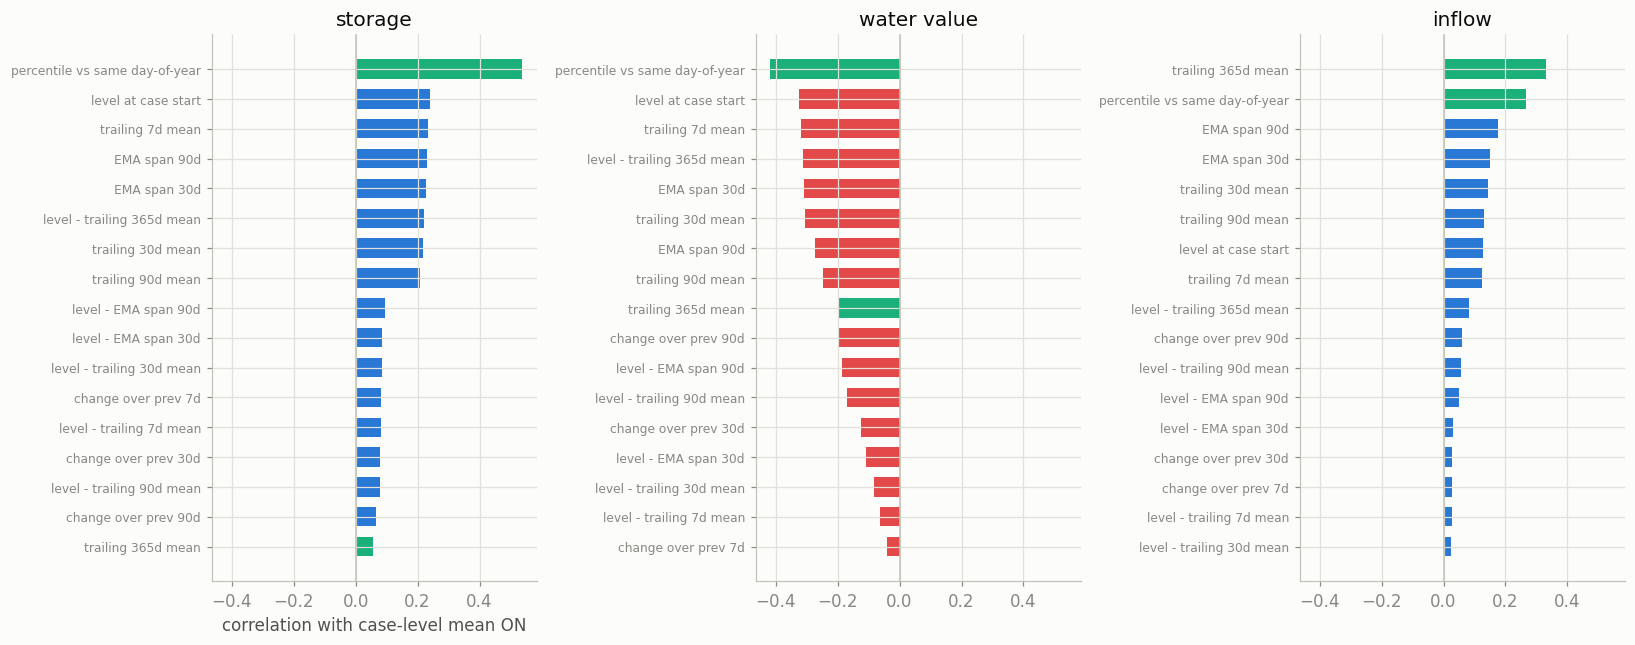

storage       level=+0.2406   best=percentile vs same day-of-year (+0.5373)
water value   level=-0.3248   best=percentile vs same day-of-year (-0.4172)
inflow        level=+0.1277   best=trailing 365d mean (+0.3314)


In [5]:
vol = pd.read_csv("../../data/kernel/Historical_volume_2015_2024.csv")
wv  = pd.read_csv("../../data/kernel/Synthetic_water_value_2015_2024.csv")
inf = pd.read_csv("../../data/kernel/Historical_inflow_1958_2025.csv")
for d in (vol, wv, inf): d["date"] = pd.to_datetime(d["date"]).dt.tz_localize(None)
vol, wv = vol.set_index("date"), wv.set_index("date")
inf_d = inf.set_index("date").resample("D").mean()
res = list(vol.columns)
series = {"storage": vol[res].sum(axis=1), "water value": wv[res].mean(axis=1),
          "inflow": inf_d[[c for c in inf_d.columns if c in res]].sum(axis=1)}

out = {}
for name, s in series.items():
    s = s.sort_index(); at = s.reindex(start.values)
    r = {"level at case start": at.to_numpy()}
    for w in [7,30,90,365]:
        ma = s.rolling(w, min_periods=2).mean().reindex(start.values)
        r[f"trailing {w}d mean"] = ma.to_numpy()
        r[f"level - trailing {w}d mean"] = at.to_numpy()-ma.to_numpy()
    for w in [7,30,90]:
        r[f"change over prev {w}d"] = (s - s.shift(w)).reindex(start.values).to_numpy()
    for sp in [30,90]:
        e = s.ewm(span=sp).mean().reindex(start.values)
        r[f"EMA span {sp}d"] = e.to_numpy()
        r[f"level - EMA span {sp}d"] = at.to_numpy()-e.to_numpy()
    doy = pd.Series(s.index.dayofyear, index=s.index)
    r["percentile vs same day-of-year"] = s.groupby(doy).rank(pct=True).reindex(start.values).to_numpy()
    out[name] = pd.Series({k: np.corrcoef(case_on.to_numpy()[~np.isnan(v)], v[~np.isnan(v)])[0,1]
                           for k, v in r.items()})

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharex=True)
for ax, (name, s) in zip(axes, out.items()):
    s = s.reindex(s.abs().sort_values().index)
    hl = ["percentile vs same day-of-year", "trailing 365d mean"]
    ax.barh(s.index, s.values, height=0.65,
            color=[CAT[2] if i in hl else (CAT[7] if v<0 else CAT[0]) for i, v in s.items()])
    ax.axvline(0, color=BASE, lw=1); ax.set_title(name)
    ax.tick_params(axis="y", labelsize=8)
axes[0].set_xlabel("correlation with case-level mean ON")
plt.tight_layout(); plt.show()
for name, s in out.items():
    b = s.abs().idxmax()
    print(f"{name:<13} level={s['level at case start']:+.4f}   best={b} ({s[b]:+.4f})")


**Finding 3 — the strongest single result in the project so far.** Normalising the slow series
against *the same time of year* transforms them:

| Series | Raw level | Best transform | Gain |
|---|---|---|---|
| Storage | +0.241 | **percentile vs. same day-of-year: +0.537** | 2.2x |
| Water value | −0.325 | **percentile vs. same day-of-year: −0.417** | 1.3x |
| Inflow | +0.128 | **trailing 365d mean: +0.331** | 2.6x |

Storage's seasonal percentile (**+0.537**) is stronger than anything else measured anywhere in
this project — including the price z-score (+0.263) that was previously our best feature
candidate. The reason is straightforward: absolute storage confounds season (every reservoir is
full in June and drawn down in April), so "is this reservoir unusually full *for the time of
year*" isolates the scarcity signal that actually drives scheduling. Inflow's trailing 365-day
mean (+0.331) is the same idea over a longer window — the wet-year/dry-year regime.

**Finding 4.** Diffs and momentum are consistently weak on the slow series too (−0.20 to +0.08),
and EMAs land within noise of plain trailing means. Neither earns its place over the seasonal
normalisations. All of these are strictly backward-looking and therefore point-in-time safe.


## Summary: every transform tested, ranked

| Rank | Transform | corr | Safe? |
|---|---|---|---|
| 1 | storage percentile vs. same day-of-year | **+0.537** | backward-looking |
| 2 | water value percentile vs. same day-of-year | **−0.417** | backward-looking |
| 3 | inflow trailing 365d mean | **+0.331** | backward-looking |
| 4 | water value level at case start | −0.325 | backward-looking |
| 5 | price z-score within case | +0.263 | in-horizon |
| 6 | price percentile within case | +0.252 | in-horizon |
| 7 | price at k=±96h (in-horizon) | ≈ −0.245 | in-horizon |
| 8 | storage level at case start | +0.241 | backward-looking |
| 9 | price − trailing 72h mean | +0.125 | backward-looking |
| 10 | price − EMA span 48h | +0.124 | backward-looking |
| 11 | price diff over 12h | +0.101 | backward-looking |

**Rule that emerges:** for *fast* series normalise against the **case**; for *slow* series
normalise against the **season**. Diffs, momentum and EMAs underperform both and are not worth
prioritising.
